In [ ]:
import os
import pandas as pd
import numpy as np

# ==========================================
# HELPER FUNCTIONS (CSV LOADER & DATE PARSER)
# ==========================================
def load_clean_csv(filepath: str) -> pd.DataFrame:
    """Auto-detects separator (',' or ';') and cleans column names."""
    with open(filepath, 'r', encoding='utf-8') as f:
        first_line = f.readline()
    sep = ';' if first_line.count(';') > first_line.count(',') else ','
    df = pd.read_csv(filepath, sep=sep)
    df.columns = df.columns.str.strip()
    return df

def parse_mixed_dates_fast(series: pd.Series) -> pd.Series:
    """Handles mixed ISO and European date formats across datasets."""
    s = series.astype(str).str.strip()
    dt = pd.to_datetime(s, format='%Y-%m-%d %H:%M:%S.%f', errors='coerce')
    dt = dt.fillna(pd.to_datetime(s, format='%Y-%m-%d %H:%M:%S', errors='coerce'))
    dt = dt.fillna(pd.to_datetime(s, format='%d.%m.%Y %H:%M', errors='coerce'))
    dt = dt.fillna(pd.to_datetime(s, format='%d.%m.%Y %H:%M:%S', errors='coerce'))
    return dt

def run_data_quality_checks(df: pd.DataFrame, table_name: str) -> None:
    """Logs missing values, duplicates, and negative value anomalies."""
    print(f"--- Data Quality Check: {table_name} ---")
    print(f"  Shape: {df.shape[0]} rows x {df.shape[1]} cols | Missing: {df.isnull().sum().sum()} | Duplicates: {df.duplicated().sum()}")
    num_cols = df.select_dtypes(include=['number']).columns
    neg_anomalies = {c: int((df[c] < 0).sum()) for c in num_cols if (df[c] < 0).sum() > 0}
    if neg_anomalies:
        print(f"  Negative Value Anomalies: {neg_anomalies}")


# ==========================================
# 1. EXTRACT FUNCTION
# ==========================================
def extract_data(paths: dict) -> dict:
    """Extracts all raw datasets from local paths and verifies initial data quality."""
    datasets = {name: load_clean_csv(path) for name, path in paths.items()}
    print("[EXTRACT] All 4 datasets extracted successfully.\n")
    for name, df in datasets.items():
        run_data_quality_checks(df, f"Raw {name.upper()}")
    return datasets


# ==========================================
# 2. TRANSFORM FUNCTION (QUALITY + FEATURE ENGINEERING)
# ==========================================
def transform_data(datasets: dict) -> pd.DataFrame:
    """Cleans timestamps, engineers Customer 360 features, imputes CRM gaps, and validates final quality."""
    sales = datasets['sales'].copy()
    crm = datasets['crm'].copy()
    survey = datasets['survey'].copy()
    logs = datasets['logs'].copy()

    # 2a. Parse mixed date formats
    date_col = 'order_date' if 'order_date' in sales.columns else 'sale_date'
    sales[date_col] = parse_mixed_dates_fast(sales[date_col])
    sales['sub_end_date'] = parse_mixed_dates_fast(sales['sub_end_date'])
    crm['recieved_datatime'] = parse_mixed_dates_fast(crm['recieved_datatime'])
    logs['datetime'] = parse_mixed_dates_fast(logs['datetime'])

    # 2b. Aggregate Sales Data (Customer-Level RFM & Delivery)
    sales_sorted = sales.sort_values(date_col)
    sales_agg = sales_sorted.groupby(['customer_id', 'customer_email'], as_index=False).agg(
        customer_county=('customer_county', 'last'),
        total_orders=('sale_id', 'nunique'),
        total_items=('quantity', 'sum'),
        total_spend=('payment_amount', 'sum'),
        avg_order_value=('payment_amount', 'mean'),
        first_order_date=(date_col, 'min'),
        last_order_date=(date_col, 'max'),
        avg_delivery_delay=('delivery_delay_days', 'mean'),
        max_delivery_delay=('delivery_delay_days', 'max'),
        undelivered_count=('is_undelivered', 'sum'),
        sub_item_ratio=('is_subscription_item', 'mean'),
        last_sub_plan=('subscription_plan', 'last'),
        last_sub_auto_renew=('sub_auto_renew', 'last')
    )

    # Normalized velocity & friction features (prevents post-churn leakage)
    sales_agg['active_span_days'] = (sales_agg['last_order_date'] - sales_agg['first_order_date']).dt.days + 1
    sales_agg['orders_per_month'] = sales_agg['total_orders'] / (sales_agg['active_span_days'] / 30.0)
    sales_agg['undelivered_rate'] = sales_agg['undelivered_count'] / sales_agg['total_orders']
    sales_agg['is_churned'] = (sales_agg['last_sub_auto_renew'] == 0).astype(int)

    # 2c. Aggregate CRM Report
    crm['platform_clean'] = crm['platform'].astype(str).str.replace(r"[\[\]']", "", regex=True)
    crm['is_complaint'] = (crm['type'] == 'complaint').astype(int)
    crm['is_query'] = (crm['type'] == 'query').astype(int)

    crm_agg = crm.groupby('customer_id', as_index=False).agg(
        total_crm_tickets=('type', 'count'),
        complaint_count=('is_complaint', 'sum'),
        query_count=('is_query', 'sum'),
        fav_crm_platform=('platform_clean', 'first')
    )
    crm_agg['complaint_ratio'] = crm_agg['complaint_count'] / crm_agg['total_crm_tickets']

    # 2d. Aggregate Server Logs
    logs['device_type'] = logs['user_agent'].astype(str).str.extract(r'\(([^;)]+)')[0].str.strip()
    logs_agg = logs.groupby('login', as_index=False).agg(
        total_sessions=('session_id', 'nunique'),
        unique_ips=('ip', 'nunique'),
        primary_device=('device_type', 'first')
    )

    # 2e. Prepare Survey Data
    survey['income_min_k'] = survey['reported_income'].astype(str).str.extract(r'(\d+)').astype(float)

    # 2f. Merge into Master Customer 360 Table
    master_df = sales_agg.merge(crm_agg, on='customer_id', how='left')
    master_df = master_df.merge(logs_agg, left_on='customer_email', right_on='login', how='left')
    master_df = master_df.merge(survey, left_on='customer_email', right_on='email', how='left')

    # Domain-driven imputation for customers with zero CRM tickets
    crm_zero_cols = ['total_crm_tickets', 'complaint_count', 'query_count', 'complaint_ratio']
    master_df[crm_zero_cols] = master_df[crm_zero_cols].fillna(0)
    master_df['fav_crm_platform'] = master_df['fav_crm_platform'].fillna('No_Contact')

    # Normalized interaction ratios
    master_df['sessions_per_order'] = master_df['total_sessions'] / master_df['total_orders']
    master_df['complaints_per_order'] = master_df['complaint_count'] / master_df['total_orders']

    # Drop IDs, raw dates, and target-leaking columns
    drop_cols = [
        'customer_id', 'customer_email', 'login', 'email', 'reported_income',
        'first_order_date', 'last_order_date', 'last_sub_auto_renew'
    ]
    final_df = master_df.drop(columns=drop_cols)

    # Round float columns for clean schema
    float_cols = final_df.select_dtypes(include=['float64']).columns
    final_df[float_cols] = final_df[float_cols].round(2)

    # Final Data Quality Assertion
    print("\n[TRANSFORM] Feature engineering completed.")
    run_data_quality_checks(final_df, "Final Customer 360 ML Dataset")
    assert final_df.isnull().sum().sum() == 0, "Data Quality Error: Unexpected nulls found!"

    return final_df


# ==========================================
# 3. LOAD FUNCTION (WRITES PARQUET TO OUTPUT FOLDER)
# ==========================================
def load_data(df: pd.DataFrame, parquet_path: str, csv_backup_path: str = None) -> None:
    """Writes the final transformed dataset as a Parquet file in the output directory."""
    os.makedirs(os.path.dirname(parquet_path), exist_ok=True)
    df.to_parquet(parquet_path, engine='pyarrow', index=False)

    if csv_backup_path:
        os.makedirs(os.path.dirname(csv_backup_path), exist_ok=True)
        df.to_csv(csv_backup_path, index=False)

    verify_df = pd.read_parquet(parquet_path)
    print(f"\n[LOAD] Parquet saved to: {parquet_path}")
    print(f"[LOAD] Verified Parquet Shape: {verify_df.shape[0]} rows x {verify_df.shape[1]} columns")


# ==========================================
# EXECUTE ETL PIPELINE
# ==========================================
if __name__ == "__main__":
    DATA_PATHS = {
        'sales': r'C:\Users\berkay\source\repos\customer-churn-prediction\data\processed_sales.csv',
        'crm': r'C:\Users\berkay\OneDrive - student.cankaya.edu.tr\Masaüstü\damn_belgeler\uk\herts\data eng\project\PerfectPetClub_CRM_report.csv',
        'survey': r'C:\Users\berkay\OneDrive - student.cankaya.edu.tr\Masaüstü\damn_belgeler\uk\herts\data eng\project\PerfectPetClub_survey.csv',
        'logs': r'C:\Users\berkay\OneDrive - student.cankaya.edu.tr\Masaüstü\damn_belgeler\uk\herts\data eng\project\PerfectPetClub_server_log.csv'
    }

    OUTPUT_PARQUET = r'C:\Users\berkay\source\repos\customer-churn-prediction\output\customer_360_features.parquet'
    BACKUP_CSV = r'C:\Users\berkay\source\repos\customer-churn-prediction\data\customer_360_features.csv'

    raw_tables = extract_data(DATA_PATHS)
    final_df = transform_data(raw_tables)
    load_data(final_df, OUTPUT_PARQUET, BACKUP_CSV)

    display(final_df.head())

[EXTRACT] All 4 datasets extracted successfully.

--- Data Quality Check: Raw SALES ---
  Shape: 59759 rows x 29 cols | Missing: 2180 | Duplicates: 741
--- Data Quality Check: Raw CRM ---
  Shape: 7585 rows x 4 cols | Missing: 0 | Duplicates: 0
--- Data Quality Check: Raw SURVEY ---
  Shape: 221 rows x 5 cols | Missing: 0 | Duplicates: 0
--- Data Quality Check: Raw LOGS ---
  Shape: 67249 rows x 5 cols | Missing: 0 | Duplicates: 0

[TRANSFORM] Feature engineering completed.
--- Data Quality Check: Final Customer 360 ML Dataset ---
  Shape: 221 rows x 28 cols | Missing: 0 | Duplicates: 0

[LOAD] Parquet saved to: C:\Users\berkay\source\repos\customer-churn-prediction\output\customer_360_features.parquet
[LOAD] Verified Parquet Shape: 221 rows x 28 columns


,customer_county,total_orders,total_items,total_spend,avg_order_value,avg_delivery_delay,max_delivery_delay,undelivered_count,sub_item_ratio,last_sub_plan,...,complaint_ratio,total_sessions,unique_ips,primary_device,nps_recommend,satisfaction_score,online_comparison_freq,income_min_k,sessions_per_order,complaints_per_order
0,Berkshire,20,46,161096,4027.40,0.05,1.0,0,0.02,SuperSaver,...,0.67,48,48,Tablet,8,6,5,26.0,2.40,0.10
1,Oxfordshire,253,748,3110183,4748.37,0.04,3.0,0,0.02,SuperSaver,...,0.47,1085,1085,Tablet,5,8,9,34.0,4.29,0.08
2,Worcestershire,304,824,3409993,4789.32,0.04,3.0,0,0.02,Premium,...,0.54,624,624,Tablet,9,5,5,26.0,2.05,0.30
3,Kent,1055,7362,45511987,9291.95,0.09,4.0,0,0.00,Premium,...,0.47,1540,1540,Tablet,9,3,5,198.0,1.46,0.13
4,Hertfordshire,44,116,465845,4802.53,0.12,3.0,0,0.04,SuperSaver,...,0.20,388,388,Mobile,0,8,10,42.0,8.82,0.02


is_churned
0    135
1     86
Name: count, dtype: int64

Churn Rate (%):
is_churned
0    61.09
1    38.91
Name: proportion, dtype: float64


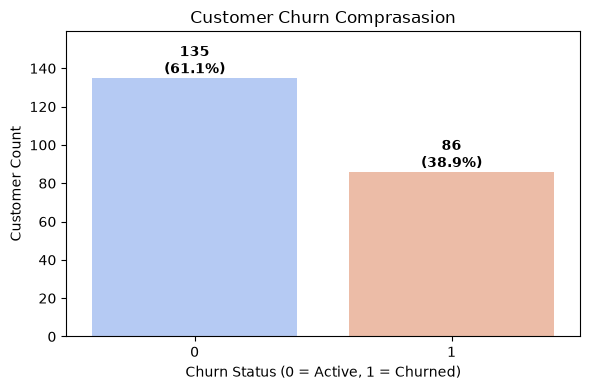

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Print exact counts and percentages
print(final_df['is_churned'].value_counts())
print("\nChurn Rate (%):")
print((final_df['is_churned'].value_counts(normalize=True) * 100).round(2))

# 2. Plot Churn Distribution
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='is_churned', hue='is_churned', data=final_df, palette='coolwarm', legend=False)

# Add count and percentage labels on top of bars
total = len(final_df)
for p in ax.patches:
    count = int(p.get_height())
    percentage = f'{100 * count / total:.1f}%'
    ax.annotate(f'{count}\n({percentage})',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title('Customer Churn Comprasasion')
plt.xlabel('Churn Status (0 = Active, 1 = Churned)')
plt.ylabel('Customer Count')
plt.ylim(0, final_df['is_churned'].value_counts().max() * 1.18)
plt.tight_layout()
plt.show()

In [10]:
final_df.groupby("is_churned")["total_orders"].mean()

is_churned
0    121.859259
1     78.337209
Name: total_orders, dtype: float64

Text(0, 0.5, 'mean')

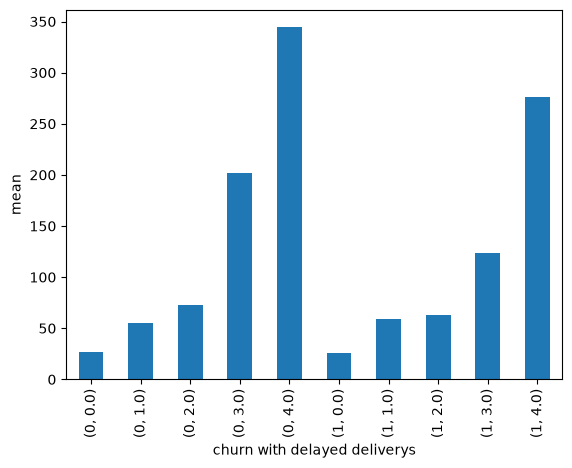

In [11]:
final_df.groupby(["is_churned" , "max_delivery_delay"])["total_orders"].mean().plot(kind="bar")
plt.xlabel("churn with delayed deliverys")
plt.ylabel("mean")

In [12]:
final_df.isnull().sum()

customer_county           0
total_orders              0
total_items               0
total_spend               0
avg_order_value           0
avg_delivery_delay        0
max_delivery_delay        0
undelivered_count         0
sub_item_ratio            0
last_sub_plan             0
active_span_days          0
orders_per_month          0
undelivered_rate          0
is_churned                0
total_crm_tickets         0
complaint_count           0
query_count               0
fav_crm_platform          0
complaint_ratio           0
total_sessions            0
unique_ips                0
primary_device            0
nps_recommend             0
satisfaction_score        0
online_comparison_freq    0
income_min_k              0
sessions_per_order        0
complaints_per_order      0
dtype: int64

In [13]:
# 1. Fill numerical CRM columns with 0 (no support interactions recorded)
crm_num_cols = [
    'total_crm_tickets',
    'complaint_count',
    'query_count',
    'complaint_ratio',
    'fav_crm_platform',
    'complaints_per_order'
]
final_df[crm_num_cols] = final_df[crm_num_cols].fillna(0)

# 2. Fill categorical CRM platform with 'No_Contact'
final_df['fav_crm_platform'] = final_df['fav_crm_platform'].fillna('No_Contact')

# 3. Verify that all missing values are resolved
print(final_df.isnull().sum())

# Round float columns to 2 decimal places for clean display
float_cols = final_df.select_dtypes(include=['float64']).columns
final_df[float_cols] = final_df[float_cols].round(2)

# Save processed features inside your repo's data folder
output_path = r'C:\Users\berkay\source\repos\customer-churn-prediction\data\customer_360_features.csv'
final_df.to_csv(output_path, sep=';', decimal=',', index=False)

print("Latest Final ML Dataset Shape:", final_df.shape)
print("Total null values:", final_df.isnull().sum().sum())
final_df.head()

customer_county           0
total_orders              0
total_items               0
total_spend               0
avg_order_value           0
avg_delivery_delay        0
max_delivery_delay        0
undelivered_count         0
sub_item_ratio            0
last_sub_plan             0
active_span_days          0
orders_per_month          0
undelivered_rate          0
is_churned                0
total_crm_tickets         0
complaint_count           0
query_count               0
fav_crm_platform          0
complaint_ratio           0
total_sessions            0
unique_ips                0
primary_device            0
nps_recommend             0
satisfaction_score        0
online_comparison_freq    0
income_min_k              0
sessions_per_order        0
complaints_per_order      0
dtype: int64
Latest Final ML Dataset Shape: (221, 28)
Total null values: 0


,customer_county,total_orders,total_items,total_spend,avg_order_value,avg_delivery_delay,max_delivery_delay,undelivered_count,sub_item_ratio,last_sub_plan,...,complaint_ratio,total_sessions,unique_ips,primary_device,nps_recommend,satisfaction_score,online_comparison_freq,income_min_k,sessions_per_order,complaints_per_order
0,Berkshire,20,46,161096,4027.40,0.05,1.0,0,0.02,SuperSaver,...,0.67,48,48,Tablet,8,6,5,26.0,2.40,0.10
1,Oxfordshire,253,748,3110183,4748.37,0.04,3.0,0,0.02,SuperSaver,...,0.47,1085,1085,Tablet,5,8,9,34.0,4.29,0.08
2,Worcestershire,304,824,3409993,4789.32,0.04,3.0,0,0.02,Premium,...,0.54,624,624,Tablet,9,5,5,26.0,2.05,0.30
3,Kent,1055,7362,45511987,9291.95,0.09,4.0,0,0.00,Premium,...,0.47,1540,1540,Tablet,9,3,5,198.0,1.46,0.13
4,Hertfordshire,44,116,465845,4802.53,0.12,3.0,0,0.04,SuperSaver,...,0.20,388,388,Mobile,0,8,10,42.0,8.82,0.02


In [ ]:
# Overwrite the CSV file with the cleaned DataFrame (zero missing values)
output_path = r'C:\Users\berkay\source\repos\customer-churn-prediction\data\customer_360_features.csv'
final_df.to_csv(output_path, index=False)

# Double-check by reading back from disk
check_df = pd.read_csv(output_path)
print("Total null values in saved CSV:", check_df.isnull().sum().sum())

Total null values in saved CSV: 0


In [14]:
final_df.duplicated().sum()

np.int64(0)

In [15]:
final_df.columns

Index(['customer_county', 'total_orders', 'total_items', 'total_spend',
       'avg_order_value', 'avg_delivery_delay', 'max_delivery_delay',
       'undelivered_count', 'sub_item_ratio', 'last_sub_plan',
       'active_span_days', 'orders_per_month', 'undelivered_rate',
       'is_churned', 'total_crm_tickets', 'complaint_count', 'query_count',
       'fav_crm_platform', 'complaint_ratio', 'total_sessions', 'unique_ips',
       'primary_device', 'nps_recommend', 'satisfaction_score',
       'online_comparison_freq', 'income_min_k', 'sessions_per_order',
       'complaints_per_order'],
      dtype='object')

In [16]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 221 entries, 0 to 220
Data columns (total 28 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_county         221 non-null    object 
 1   total_orders            221 non-null    int64  
 2   total_items             221 non-null    int64  
 3   total_spend             221 non-null    int64  
 4   avg_order_value         221 non-null    float64
 5   avg_delivery_delay      221 non-null    float64
 6   max_delivery_delay      221 non-null    float64
 7   undelivered_count       221 non-null    int64  
 8   sub_item_ratio          221 non-null    float64
 9   last_sub_plan           221 non-null    object 
 10  active_span_days        221 non-null    int64  
 11  orders_per_month        221 non-null    float64
 12  undelivered_rate        221 non-null    float64
 13  is_churned              221 non-null    int64  
 14  total_crm_tickets       221 non-null    fl

In [17]:
final_df.describe()

,total_orders,total_items,total_spend,avg_order_value,avg_delivery_delay,max_delivery_delay,undelivered_count,sub_item_ratio,active_span_days,orders_per_month,...,query_count,complaint_ratio,total_sessions,unique_ips,nps_recommend,satisfaction_score,online_comparison_freq,income_min_k,sessions_per_order,complaints_per_order
count,221.000000,221.000000,2.210000e+02,221.000000,221.000000,221.000000,221.0,221.000000,221.000000,221.000000,...,221.000000,221.000000,221.000000,221.000000,221.000000,221.000000,221.000000,221.000000,221.000000,221.000000
mean,104.923077,325.606335,1.473502e+06,4667.571176,0.051448,1.796380,0.0,0.055520,131.185520,24.418100,...,16.959276,0.462534,304.294118,304.289593,5.805430,4.760181,6.090498,40.823529,3.978100,0.182127
std,127.130815,637.558171,3.803155e+06,1118.887912,0.058610,1.313976,0.0,0.123573,100.722558,15.665981,...,22.881576,0.242408,290.885856,290.877071,2.883049,3.342760,2.826972,23.088576,2.965778,0.199051
min,1.000000,1.000000,2.990000e+02,299.000000,0.000000,0.000000,0.0,0.000000,1.000000,3.000000,...,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,18.000000,1.000000,0.000000
25%,26.000000,63.000000,2.486460e+05,4410.020000,0.000000,0.000000,0.0,0.020000,48.000000,12.780000,...,2.000000,0.360000,81.000000,81.000000,3.000000,2.000000,4.000000,26.000000,2.070000,0.050000
50%,62.000000,176.000000,7.214450e+05,4644.070000,0.040000,2.000000,0.0,0.030000,105.000000,21.690000,...,8.000000,0.500000,198.000000,198.000000,6.000000,5.000000,6.000000,34.000000,2.960000,0.110000
75%,136.000000,357.000000,1.481972e+06,4859.170000,0.070000,3.000000,0.0,0.050000,204.000000,33.000000,...,23.000000,0.580000,449.000000,449.000000,8.000000,8.000000,9.000000,46.000000,4.670000,0.250000
max,1055.000000,7362.000000,4.551199e+07,10422.420000,0.290000,4.000000,0.0,1.000000,314.000000,101.120000,...,149.000000,1.000000,1540.000000,1540.000000,10.000000,10.000000,10.000000,198.000000,19.000000,1.000000


In [ ]:
count_col = []
hist_col = []
for column in final_df.columns:
    unique_value = final_df[column].nunique()
    if unique_value <= 20:
        count_col.append(column)
    else:
        hist_col.append(column)   

In [26]:
%pip install matplotlib
%pip install seaborn



Note: you may need to restart the kernel to use updated packages.
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


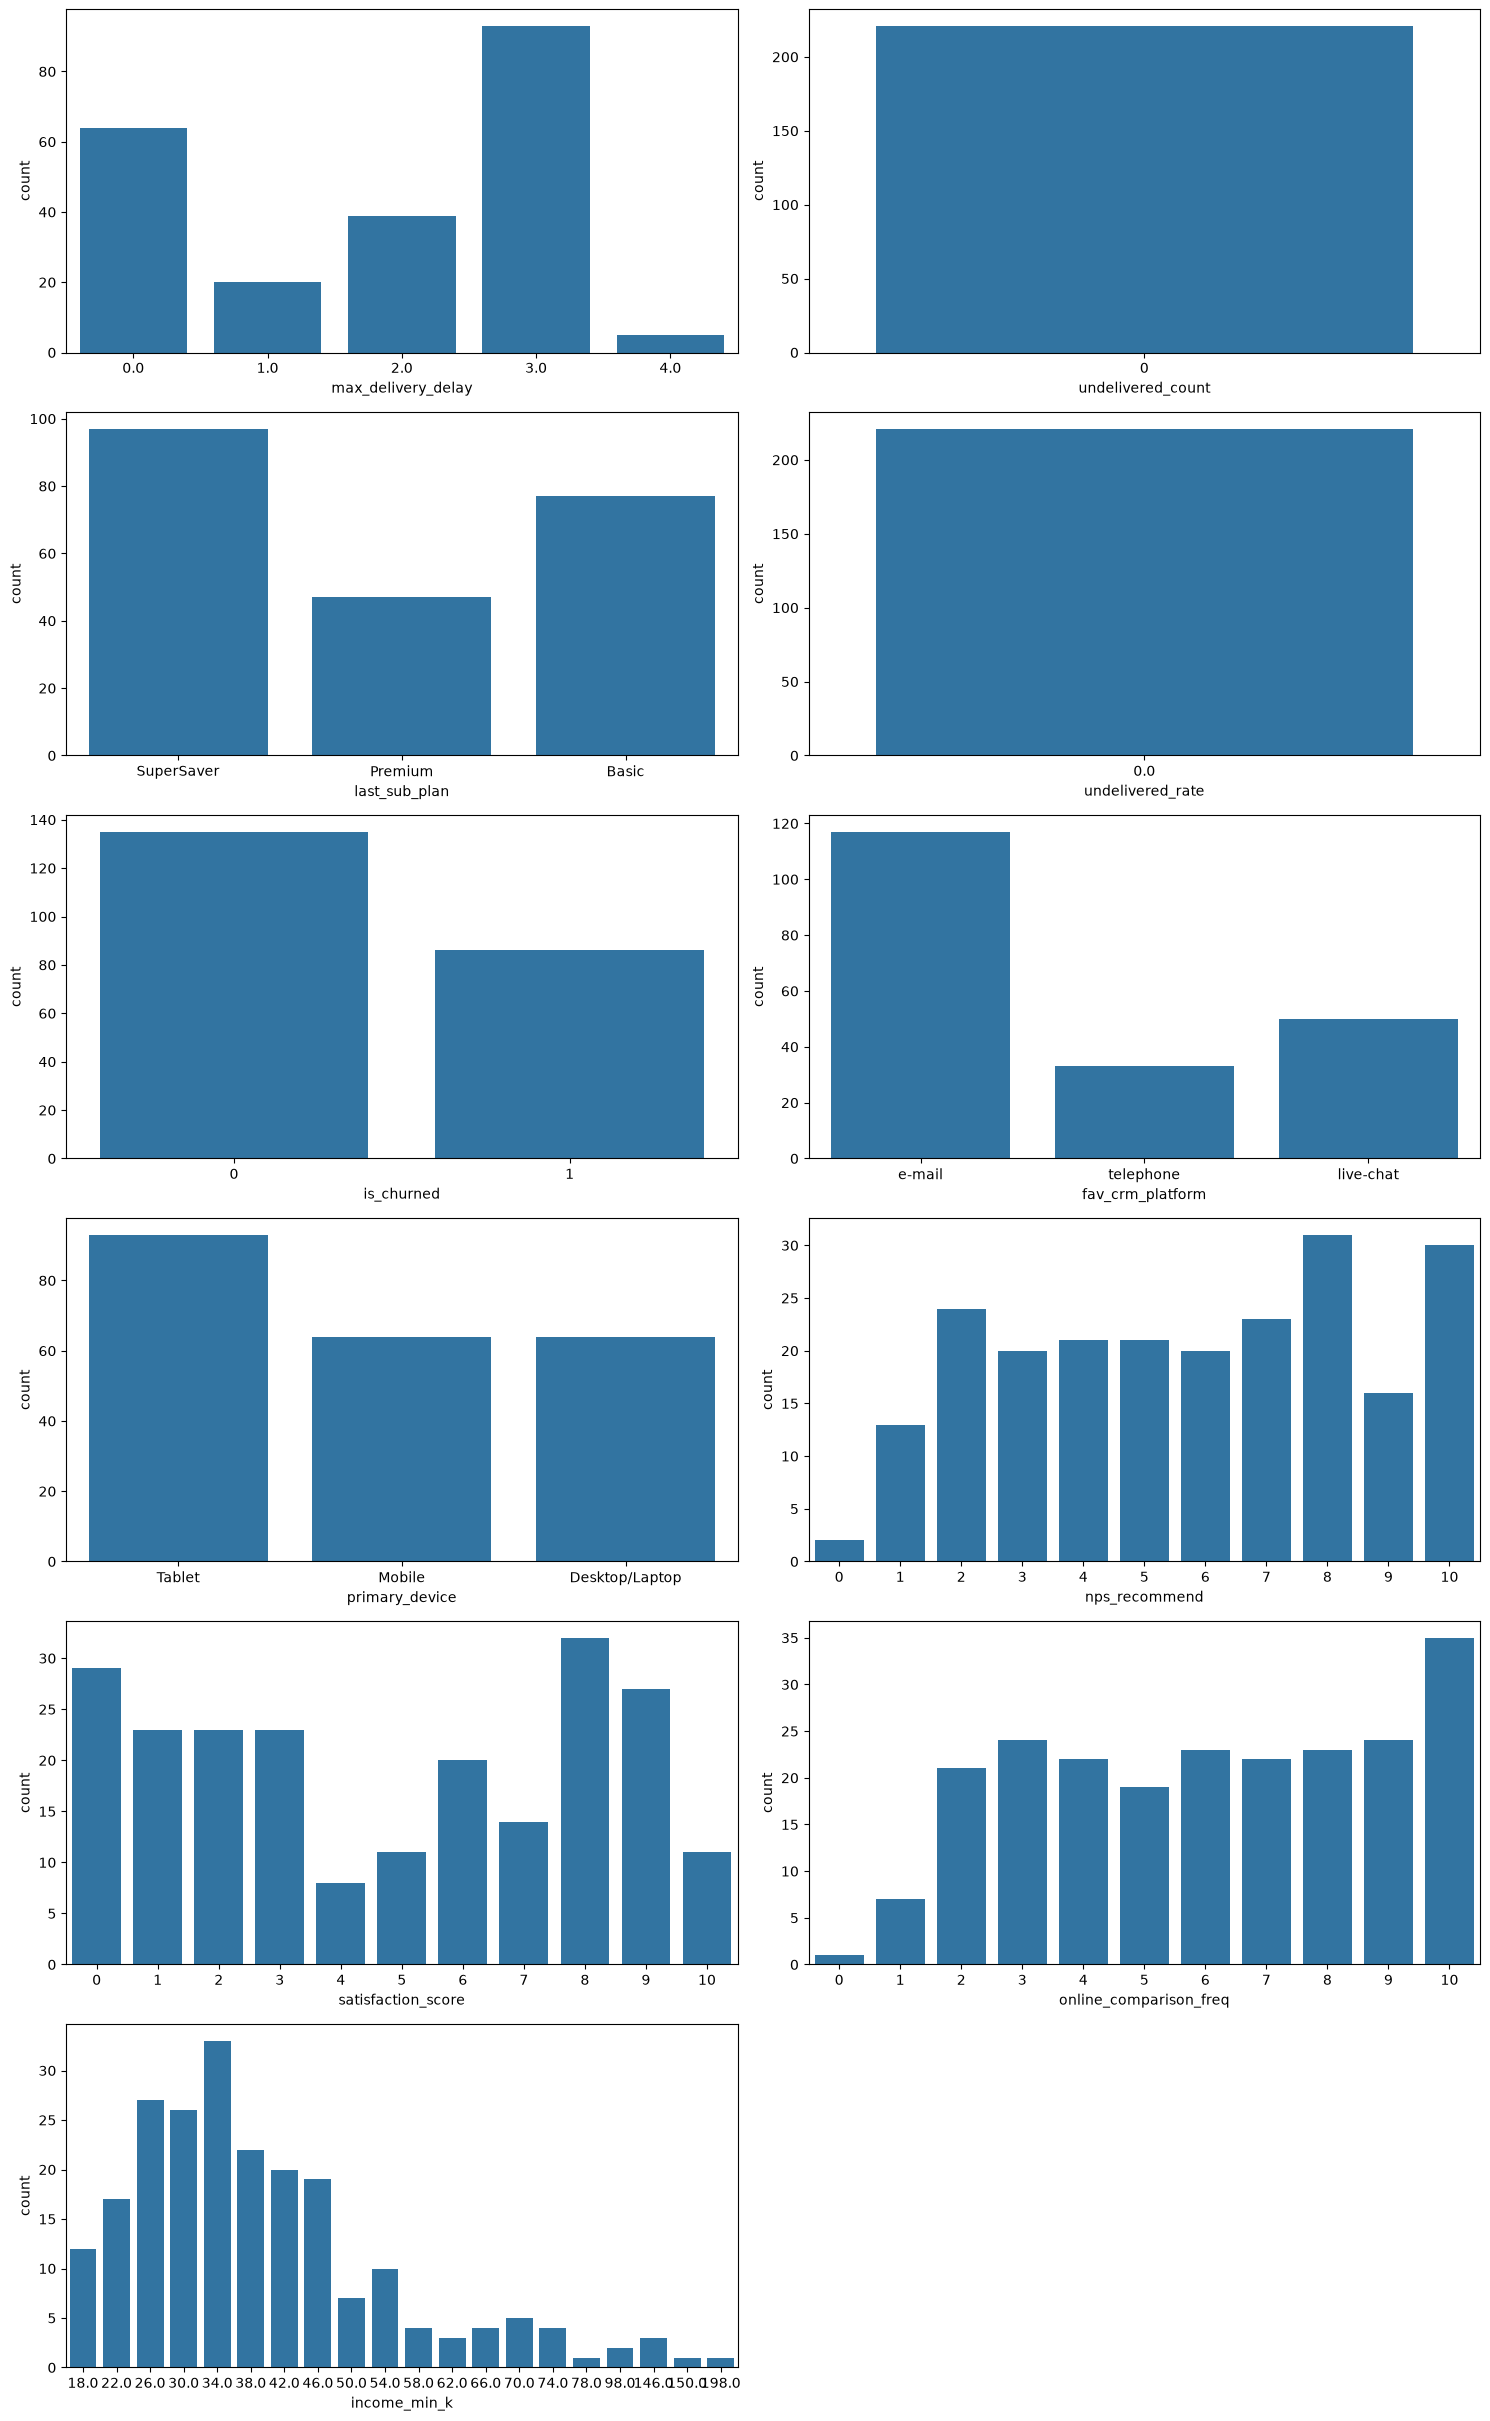

In [ ]:
import matplotlib.pyplot as plt 
import seaborn as sns 


plt.figure(figsize=(15,40))
plot_num = 1
for col in count_col:
    plt.subplot(10,2,plot_num)
    sns.countplot(data=final_df, x=col)
    plot_num += 1
    plt.tight_layout()

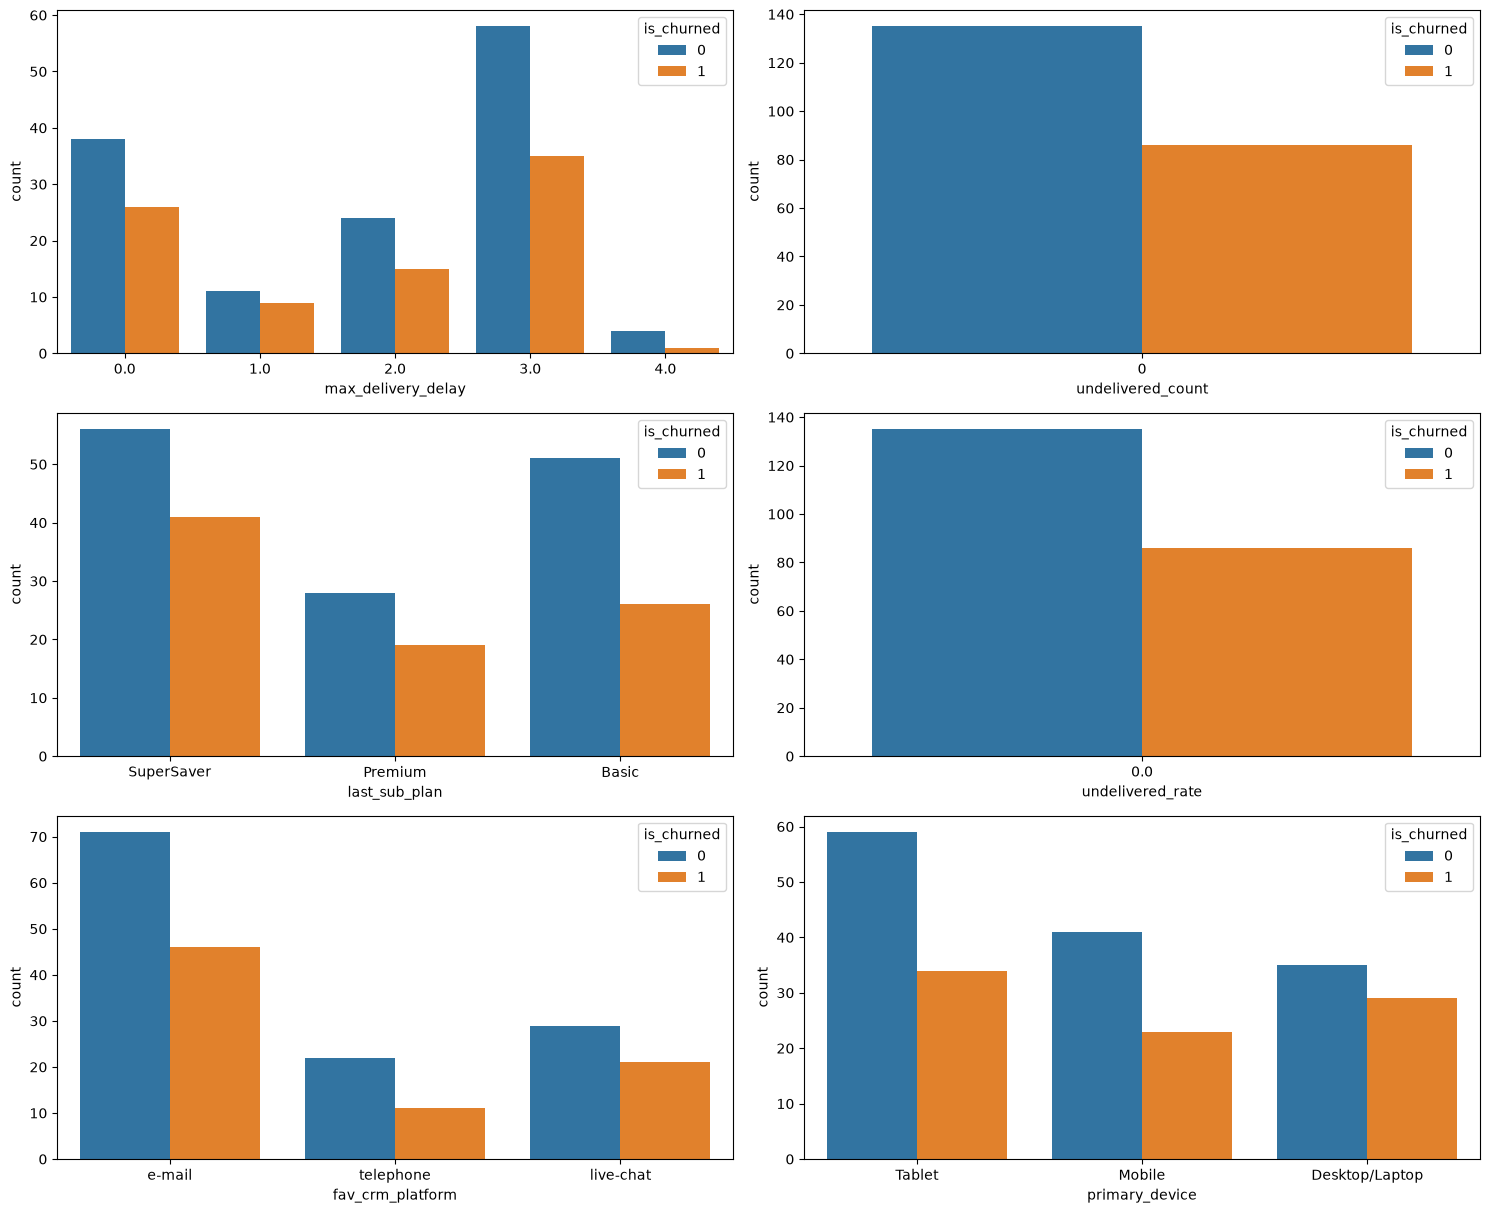

In [ ]:
plt.figure(figsize=(15,40))
plot_num = 1
for col in count_col:
    if final_df[col].nunique() <= 8 and col != "is_churned":
        plt.subplot(10,2,plot_num)
        sns.countplot(data=final_df, x=col, hue="is_churned")
        plot_num += 1
        plt.tight_layout()

In [ ]:
numeric_collumns_data = final_df.select_dtypes(include = ["number"])
numeric_collumns_data.corr()